In [1]:
from collections import defaultdict
import numpy as np
from dezerogym.gridworld import GridWorld


# Dynamic Programming(DP)법

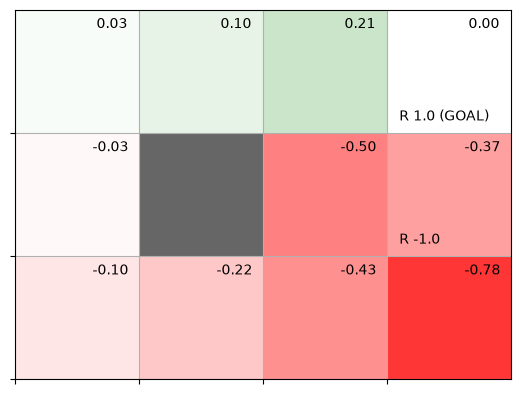

In [2]:
from collections import defaultdict

# 상태-행동 쌍을 기반으로 한 번의 벨만 기대값 갱신을 수행하는 함수
# pi: 정책 (상태별 행동 확률)
# V: 현재 가치 함수
# env: GridWorld 환경
# gamma: 할인율
def eval_onestep(pi, V, env, gamma=0.9):
    # 모든 상태를 순회하면서 각 상태의 새로운 가치를 계산
    for state in env.states():
        # 목표 상태는 종료 상태이므로 가치가 0
        if state == env.goal_state:
            V[state] = 0
            continue

        # 현재 상태에서 가능한 행동과 그 행동을 선택할 확률
        action_probs = pi[state]
        new_V = 0

        # 각 행동에 대해 기대값을 계산
        for action, action_prob in action_probs.items():
            # 행동을 취했을 때의 다음 상태와 즉시 보상
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)

            # 상태 s에서 행동 a를 수행할 때의 기대 가치s
            # = 즉시 보상 + 할인된 미래 가치
            new_V += action_prob * (r + gamma * V[next_state])

        # 갱신된 상태 가치를 저장
        V[state] = new_V
    return V


# 정책 평가: 가치 함수가 수렴할 때까지 반복적으로 업데이트
# threshold: 수렴 기준. 최대 변화량이 이 값보다 작아지면 종료
def policy_eval(pi, V, env, gamma, threshold=0.001):
    while True:
        # 이전 가치 함수를 저장해 비교용으로 사용
        old_V = V.copy()

        # 한 번의 벨만 기대 갱신 수행
        V = eval_onestep(pi, V, env, gamma)

        # 최대 가치 변화량(delta)을 계산
        delta = 0
        for state in V.keys():
            t = abs(V[state] - old_V[state])
            if delta < t:
                delta = t

        # 변화량이 너무 작아지면 수렴했다고 판단하고 종료
        if delta < threshold:
            break

    return V

# 환경 객체와 할인율 설정
env = GridWorld()
gamma = 0.9

# 균등 랜덤 정책:
# 각 상태에서 네 가지 행동을 동일한 확률(0.25)로 선택
pi = {}
for state in env.states():
    pi[state] = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}

# 가치 함수 초기화: 모든 상태의 가치 0으로 시작
V = {}
for state in env.states():
    V[state] = 0.0

# 정책 평가를 수행해서 가치 함수를 계산
V = policy_eval(pi, V, env, gamma)

# 계산된 가치 함수를 시각화
env.render_v(V)

# Monte Carlo(MC)법

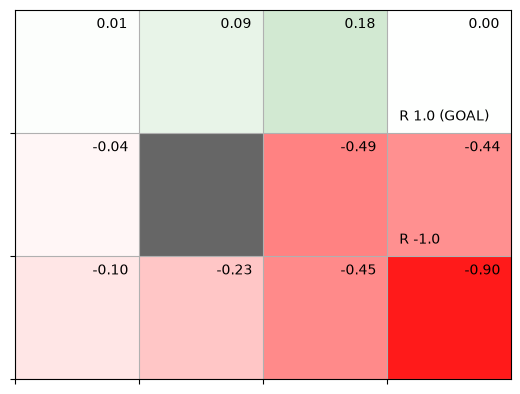

In [4]:

class RandomAgent:
    def __init__(self):
        self.gamma = 0.9
        self.action_size = 4
        # 균등 랜덤 정책:
        # 각 상태에서 네 가지 행동을 동일한 확률(0.25)로 선택
        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.V = defaultdict(lambda: 0)
        self.cnts = defaultdict(lambda: 0)
        self.memory = []

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        self.memory.clear()

    def eval(self):
        G = 0
        for data in reversed(self.memory):
            state, action, reward = data
            G = self.gamma * G + reward
            self.cnts[state] += 1
            self.V[state] += (G - self.V[state]) / self.cnts[state]


env = GridWorld()
agent = RandomAgent()

episodes = 1000
for episode in range(episodes): # 에피소드 1000번 수행
    state = env.reset()
    agent.reset()

    while True:
        action = agent.get_action(state)  # 행동 선택
        # print(f"Episode: {episode}, State: {state}, Action: {action}")

        next_state, reward, done = env.step(action) # 행동 수행

        agent.add(state, action, reward) # (상태, 행동, 보상) 저장
        if done: # 목표에 도달 시
            agent.eval() # 몬테카를로법으로 가치 함수 갱신
            break # 다음 에피소드 시작

        state = next_state

env.render_v(agent.V)

# Temporal Difference (TD)법

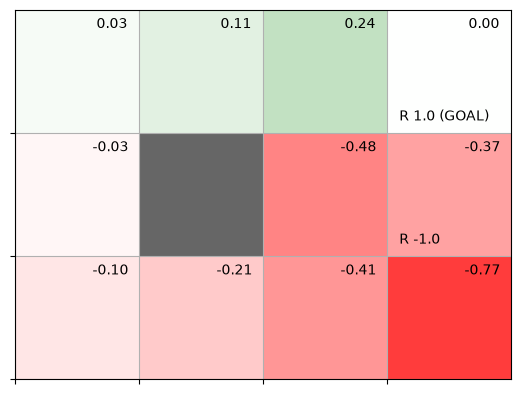

In [5]:


class TdAgent:
    def __init__(self):
        self.gamma = 0.9       # 미래 보상의 할인율
        self.alpha = 0.01       # 가치 함수 업데이트 학습률
        self.action_size = 4    # 가능한 행동의 개수

        # 초기 정책: 각 행동을 동일한 확률로 선택
        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)

        # 상태별 가치 함수. 방문하지 않은 상태의 초기값은 0
        self.V = defaultdict(lambda: 0)

    def get_action(self, state):
        """현재 상태에서 정책에 따라 행동을 무작위로 선택합니다."""
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def eval(self, state, reward, next_state, done):
        """TD(0) 방식으로 현재 상태의 가치를 업데이트합니다."""
        # 에피소드가 끝나면 다음 상태의 가치는 0으로 처리
        next_V = 0 if done else self.V[next_state]

        # 현재 보상과 다음 상태 가치로 TD 목표값 계산
        target = reward + self.gamma * next_V

        # TD 오차를 이용해 가치 함수 업데이트
        self.V[state] += (target - self.V[state]) * self.alpha


# GridWorld 환경과 에이전트 생성
env = GridWorld()
agent = TdAgent()

episodes = 1000
# 지정한 에피소드 수만큼 학습
for episode in range(episodes):
    state = env.reset()  # 환경을 초기화하고 시작 상태를 가져옴

    while True:
        action = agent.get_action(state)
        # print(f"Episode: {episode}, State: {state}, Action: {action}")

        # 행동을 실행하고 다음 상태, 보상, 종료 여부를 확인
        next_state, reward, done = env.step(action)

        # 관찰한 결과를 바탕으로 상태 가치 업데이트
        agent.eval(state, reward, next_state, done)

        if done:
            break

        state = next_state  # 다음 반복을 위해 현재 상태 갱신

# 학습한 상태 가치 함수를 환경에 표시
env.render_v(agent.V)